ESTADÍSTICAS DESCRIPTIVAS:


,actual_happiness_score,gdp,family,health,freedom,generosity,corruption,year
count,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000
mean,5.379018,0.916047,1.078392,0.612416,0.411091,0.218576,0.125275,2016.993606
std,1.127456,0.407340,0.329548,0.248309,0.152880,0.122321,0.105844,1.417364
min,2.693000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2015.000000
25%,4.509750,0.606500,0.869363,0.440183,0.309768,0.130000,0.054000,2016.000000
50%,5.322000,0.982205,1.124735,0.647310,0.431000,0.201982,0.090905,2017.000000
75%,6.189500,1.236187,1.327250,0.808000,0.531000,0.278832,0.155861,2018.000000
max,7.769000,2.096000,1.644000,1.141000,0.724000,0.838075,0.551910,2019.000000


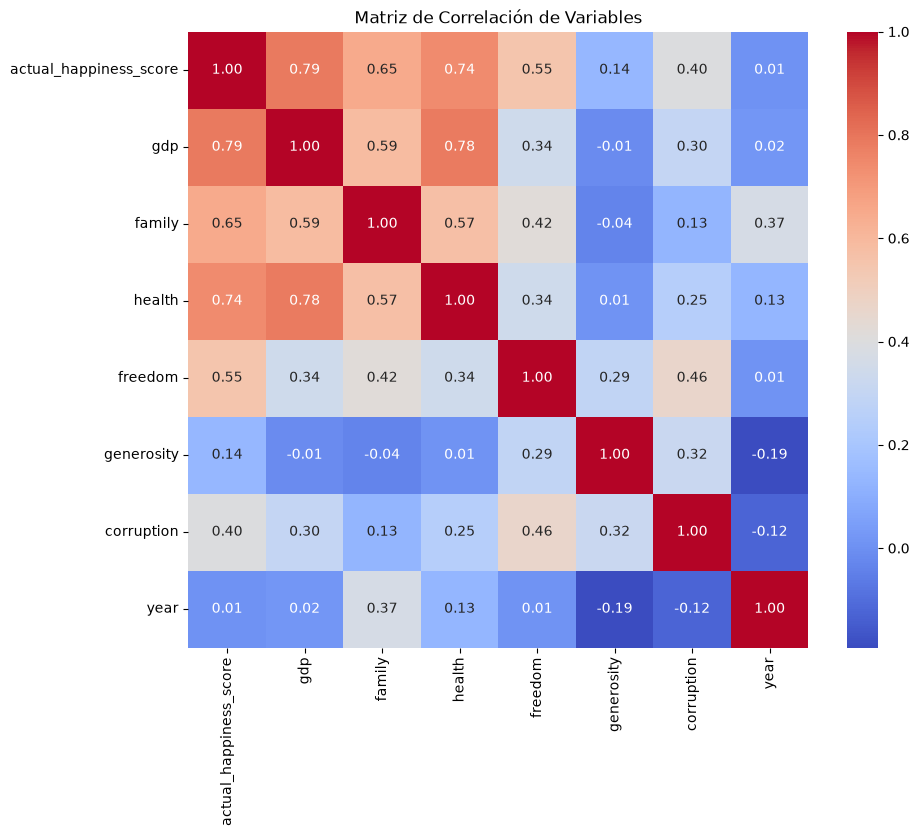

TypeError: got an unexpected keyword argument 'squared'

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import os

# 1. Cargar los datos procesados
df = pd.read_csv('../data/processed/unified_happiness.csv')

# ==========================================
# PASO 3: FEATURE ENGINEERING
# ==========================================
print("ESTADÍSTICAS DESCRIPTIVAS:")
display(df.describe())

# Visualizar correlaciones para justificar la selección de características
plt.figure(figsize=(10, 8))
numeric_df = df.drop(columns=['country']) # Excluimos texto para la correlación
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlación de Variables")
plt.show()

# Selección de características (evitando target leakage al separar el score)
features = ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
X = df[features]
y = df['actual_happiness_score']

# ==========================================
# PASO 4: TRAIN REGRESSION MODEL
# ==========================================
# Dividir los datos en 70% entrenamiento y 30% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Crear un Pipeline reproducible con preprocesamiento (Scaler) y el modelo
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Entrenar el modelo
pipeline.fit(X_train, y_train)

# Generar predicciones con el set de pruebas
y_pred = pipeline.predict(X_test)

# Evaluar el modelo con las métricas sugeridas
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
r2 = r2_score(y_test, y_pred)

print("\nMÉTRICAS DE EVALUACIÓN:")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2: {r2:.4f}")

# Serializar y guardar el modelo + preprocesamiento
os.makedirs('../models', exist_ok=True)
model_path = '../models/model.pkl'
joblib.dump(pipeline, model_path)
print(f"\n¡Pipeline pre-entrenado guardado exitosamente en: {model_path}!")